# M08-2 | From Q/DQ Graph to `.pte`: Lowering, File Size, Runtime Execution

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bobondemon/pt2e_quantize_and_deploy/blob/main/en/m08_xnnpack_executorch/02_export_to_pte.ipynb)

All three treatments in M07 stay inside PyTorch and produce no int8 kernel. This notebook takes Route A (M07 overview): hand the Q/DQ graph to ExecuTorch's XNNPACK backend, produce the deployment file `.pte`, and run it with the ExecuTorch runtime.

```text
export (static shape) → PT2E                Q/DQ graph (executorch XNNPACKQuantizer, M08-1)
  → to_edge_transform_and_lower             XnnpackPartitioner carves out subgraphs, compiled into a delegate
  → to_executorch                           memory planning, serialize to .pte
  → ExecuTorch runtime                      load the .pte, run it
```

- **A.** Graphs before and after lowering: where the ops on the Q/DQ graph went; inside the delegate, the nodes XNNPACK actually executes.
- **B.** `.pte` file size: fp32 vs int8.
- **C.** Run the `.pte` with the ExecuTorch runtime; what happens with a different batch size.

The terms at each step (Edge dialect, partitioner, delegate, memory planning) are in the [M08 overview](00_overview.ipynb). This notebook needs executorch (`uv sync --group executorch`).

In [1]:
#| include: false
# On Google Colab: download this tutorial's code and install the packages (takes a few minutes the first time).
# On your own machine (see the README for the environment), this cell does nothing.
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    repo = "/content/pt2e_quantize_and_deploy"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/bobondemon/pt2e_quantize_and_deploy.git", repo], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "--extra-index-url", "https://download.pytorch.org/whl/cpu",
                        "torch==2.14.0+cpu", "torchao==0.18.0", "onnx==1.23.0", "onnxscript==0.7.2",
                        "onnxruntime==1.30.0", "executorch==1.5.0", "tabulate", "graphviz"], check=True)
    sys.path.insert(0, repo)  # let the notebook import this tutorial's common/
    os.chdir(f"{repo}/en/m08_xnnpack_executorch")

In [2]:
import tempfile
from pathlib import Path

import torch

from common.pt2e import quiet  # must be imported before executorch (executorch imports torchao)
from common.data import trained_tiny_net
from common.env import capture_stderr, env_summary
from common.executorch_utils import PteRunner, delegation_summary, lower_to_xnnpack, xnnpack_nodes, xnnpack_ptq
from common.graph_utils import op_counts, short
from common.models import example_inputs
from common.viz import draw, table

from executorch.backends.xnnpack.partition.xnnpack_partitioner import XnnpackPartitioner  # noqa: E402
from executorch.exir import to_edge_transform_and_lower  # noqa: E402

quiet()
_ = torch.manual_seed(0)
print(env_summary())

Linux x86_64 | torch 2.14.0+cu130 | threads=1 | mkldnn=True | nnpack=True


## Starting Point: the Static-Shape Q/DQ Graph

The model is M05's `TinyConvNet` (trained). `xnnpack_ptq` is this project's wrapper (`common/executorch_utils.py`, not an executorch API); it does the PTQ familiar from M01 on, with only two differences:

- `export_module(..., dynamic_batch=False)`: turns off dynamic batch, so the graph accepts only the batch size of `example_inputs` (1 here). The reason is in section C.
- The quantizer is the executorch `XNNPACKQuantizer` (per-channel weight).

Because the batch is fixed at 1, the calibration data is also fed one sample at a time.

In [3]:
model = trained_tiny_net().eval()
x = example_inputs(1)
qdq = xnnpack_ptq(model, x)  # export (static) → prepare_pt2e → calibration → convert_pt2e
counts = op_counts(qdq)
n_before = sum(counts.values())
n_qdq = sum(v for k, v in counts.items() if "quantize" in k)
print(f"Q/DQ graph: {n_before} call_function nodes, of which {n_qdq} are q/dq")

Q/DQ graph: 42 call_function nodes, of which 28 are q/dq


## A. Lowering: Where the Ops on the Q/DQ Graph Went

Using only executorch's raw API, in three steps:

In [4]:
ep = torch.export.export(qdq, x)                                          # 1. export once more to get an ExportedProgram
edge = to_edge_transform_and_lower(ep, partitioner=[XnnpackPartitioner()])  # 2. convert to Edge dialect, carve out the delegate
pte = edge.to_executorch().buffer                                         # 3. memory planning, serialize to the bytes of the .pte
lowered = edge.exported_program().graph_module                            # the graph after step 2
print(f"GraphModule after lowering: {len(lowered.graph.nodes)} nodes; .pte {len(pte)} bytes")

GraphModule after lowering: 5 nodes; .pte 20880 bytes


Step 1 exports once more because `to_edge_transform_and_lower` takes an `ExportedProgram`, while `convert_pt2e` returns a GraphModule. This step also fixes the shape to that of `x`.
This project wraps the three steps as `lower_to_xnnpack(gm, example_inputs)`, which returns `(edge, pte)`, used by M08-3 and M08-4.

The graph after step 2 (the GraphModule after lowering):

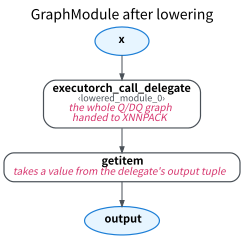

In [5]:
draw(lowered, notes={"executorch_call_delegate": "the whole Q/DQ graph\nhanded to XNNPACK",
                     "getitem": "takes a value from the delegate's output tuple"},
     title="GraphModule after lowering")

The conv, relu, and q/dq from the Q/DQ graph are gone, leaving only one `executorch_call_delegate`. `‹lowered_module_0›` is its delegate: the subgraph compiled by XNNPACK.

Which ops went into the delegate? `delegation_summary` (this project's wrapper) calls executorch's `get_delegation_info(lowered)` and counts, op by op, whether it was handed to XNNPACK or stayed in ExecuTorch. The op names are in Edge dialect spelling:

In [6]:
n_sub, n_del, n_non, by_op = delegation_summary(edge)
table([[op, d, nd] for op, (d, nd) in sorted(by_op.items())], ["op (Edge dialect name)", "handed to XNNPACK", "stays in ExecuTorch"])

op (Edge dialect name),handed to XNNPACK,stays in ExecuTorch
aten_add_tensor,1,0
aten_convolution_default,4,0
aten_linear_default,1,0
aten_max_pool2d_default,2,0
aten_mean_dim,1,0
aten_relu_default,4,0
aten_view_copy_default,1,0
getitem,0,1
quantized_decomposed_dequantize_per_channel_default,5,0
quantized_decomposed_dequantize_per_tensor_default,12,0


In [7]:
left = sorted(op for op, (_, nd) in by_op.items() if nd)
print(f"delegates: {n_sub}; Edge nodes handed to the delegate: {n_del} ({n_before} before lowering); left behind: {left}")
assert n_sub == 1 and n_del == n_before and left == ["getitem"]

delegates: 1; Edge nodes handed to the delegate: 42 (42 before lowering); left behind: ['getitem']


- All the ops before lowering went into the same delegate; the only thing left is `getitem`, which was added during lowering and is not a computation. At run time ExecuTorch calls XNNPACK just once.
- The names changed: `conv2d` has been decomposed into `convolution` in the Edge dialect, `adaptive_avg_pool2d` became `mean`, and `flatten` became `view_copy`.
- The above counts Edge nodes, q/dq included. What these nodes turn into once inside the delegate can only be seen by opening the delegate.

### Inside the Delegate: the Nodes XNNPACK Actually Executes

After `to_edge_transform_and_lower` hands the subgraph to XNNPACK, the XNNPACK backend rebuilds it as its own graph and serializes that into the `.pte`. The runtime executes this graph, not the Edge nodes above.

`xnnpack_nodes(qdq, x)` is a tool of this project (`common/executorch_utils.py`, not an executorch API): it lowers once more, intercepts the graph before XNNPACK serializes it, and lists each node's input and output dtypes, plus the output range fused into the node (clamp). It depends on executorch 1.5.0's internals and may need changes for other versions; the reader only needs to understand the printed table. The dtypes use XNNPACK's spelling: `qint8` is per-tensor int8, and `qcint8` and `qcint32` are the per-channel int8 weight and int32 bias.

In [8]:
xnn = xnnpack_nodes(qdq, x)[0]  # there is only one delegate
table(xnn, ["XNNPACK node", "input dtype", "output dtype", "output clamp"])

XNNPACK node,input dtype,output dtype,output clamp
XNNConvert,fp32,qint8,
XNNStaticTranspose,qint8,qint8,
XNNConv2d,"qint8, qcint8, qcint32",qint8,"[0, +inf]"
XNNMaxPooling2d,qint8,qint8,
XNNConv2d,"qint8, qcint8, qcint32",qint8,"[0, +inf]"
XNNConv2d,"qint8, qcint8, qcint32",qint8,
XNNAdd,"qint8, qint8",qint8,"[0, +inf]"
XNNMaxPooling2d,qint8,qint8,
XNNConv2d,"qint8, qcint8, qcint32",qint8,"[0, +inf]"
XNNGlobalAvgPooling2d,qint8,qint8,


In [9]:
names = [r[0] for r in xnn]
n_relu = sum(short(n.target) == "relu" for n in qdq.graph.nodes)
n_clamp = sum(r[3] == "[0, +inf]" for r in xnn)
print(f"Q/DQ graph: {n_before} call_function nodes ({n_qdq} q/dq) → {len(xnn)} XNNPACK nodes")
print(f"XNNConvert: {names.count('XNNConvert')}; relu on the Q/DQ graph: {n_relu}; nodes with a fused clamp: {n_clamp}")

Q/DQ graph: 42 call_function nodes (28 q/dq) → 14 XNNPACK nodes
XNNConvert: 2; relu on the Q/DQ graph: 4; nodes with a fused clamp: 4


In [10]:
assert names[0] == names[-1] == "XNNConvert" and names.count("XNNConvert") == 2
assert xnn[0][1] == "fp32" and xnn[-1][2] == "fp32" and all(r[2] == "qint8" for r in xnn[:-1])
assert n_clamp == n_relu and not any("Clamp" in n for n in names)

Each dq → op → q unit becomes one XNNPACK node, with `qint8` for both input and output:

- **q/dq are gone**: the q/dq sandwiched between two ops are not computations; only the scale and zero point on the tensor remain (which is why the dtype is `qint8` rather than fp32).
- **fp32 ↔ int8 converts only twice**: the two `XNNConvert`s at the head and tail come from the q at the graph input and the dq at the output.
- **bias became int32**: on the Q/DQ graph the bias is fp32; here it is `qcint32`.
- **relu is fused**: relu has no node of its own; it became the output clamp `[0, +inf]` of the preceding conv or add.
- **Two extra transposes**: XNNPACK's conv and pooling use the NHWC layout, so the data is converted from NCHW before the first conv and back before flatten. These two ops are not on the Q/DQ graph.

This table is a worked example of "Where q/dq Go During Lowering" in the [M08 overview](00_overview.ipynb).

## B. `.pte` File Size: fp32 vs int8

As a reference, lower the fp32 model directly without quantizing:

In [11]:
_, pte_fp32 = lower_to_xnnpack(model, x)
n_params = sum(p.numel() for p in model.parameters())
table([["fp32 .pte", len(pte_fp32), n_params * 4], ["int8 .pte", len(pte), n_params]],
      ["", ".pte bytes", "size if all parameters are stored as fp32 / int8"])

,.pte bytes,size if all parameters are stored as fp32 / int8
fp32 .pte,45968,39760
int8 .pte,20880,9940


In [12]:
ratio = len(pte) / len(pte_fp32)
print(f"The int8 .pte is {ratio:.0%} of the fp32 .pte (the model has {n_params} parameters)")
assert len(pte) < len(pte_fp32)

The int8 .pte is 45% of the fp32 .pte (the model has 9940 parameters)


- A `.pte` is a self-contained deployment file: the graph, weights, delegate data, and memory plan are all inside.
- In the int8 version the weights are stored as int8, with per-channel scales stored separately; the bias that is fp32 on the Q/DQ graph is quantized to int32 during lowering and stored (M08 overview). So the int8 estimate in the third column (1 byte per parameter) is slightly lower than the actual size.
- The rest is graph structure, the description of the XNNPACK subgraph, and the memory plan. This part does not grow in proportion to the parameter count, so the larger the model, the closer the int8-to-fp32 ratio gets to 1/4 (inference; no larger model was measured).

## C. Run with the ExecuTorch Runtime

What you hand over at deployment is the `.pte` file. Write it to a file first, then load it from the file.
`PteRunner` is this project's wrapper: `executorch.runtime.Runtime.get().load_program(...)` loads it, `load_method("forward")` gets the method, and `execute([...])` runs it (the raw API is in the M08 overview). It keeps the Program returned by `load_program` alive: if you keep only the Method and let the Program be garbage collected, the Method reads freed memory when it runs.

In [13]:
with tempfile.TemporaryDirectory() as d:
    path = Path(d) / "tiny_int8.pte"
    path.write_bytes(pte)
    runner = PteRunner(path)
    y_pte = runner(x[0])
with torch.no_grad():
    y_qdq = qdq(x[0])
out_scale = [n for n in qdq.graph.nodes if short(n.target) == "quantize_per_tensor"][-1].args[1]
print(f"input {tuple(x[0].shape)} → output {tuple(y_pte.shape)}")
print(f"Max difference from the Q/DQ graph: {(y_pte - y_qdq).abs().max():.3g} ({(y_pte - y_qdq).abs().max() / out_scale:.2f} output LSB)")

input (1, 3, 16, 16) → output (1, 4)
Max difference from the Q/DQ graph: 0.0643 (1.00 output LSB)


The output LSB is the scale of the last quantize: one step of int8. The `.pte` computes with XNNPACK's integer kernels while the Q/DQ graph simulates in fp32, so the two are not guaranteed to be bit-identical (M08 overview, "Numerical Differences from the Q/DQ Graph"); section C of M08-3 measures the difference over many inputs.

### Changing the Batch Size

The `.pte` was exported with batch 1. Try feeding batch 4. The ExecuTorch runtime's C++ layer prints the reason to stderr; this project's `capture_stderr()` (`common/env.py`) collects it so we can print it together:

In [14]:
with capture_stderr() as log:
    try:
        runner(torch.randn(4, 3, 16, 16))
        error = None
    except RuntimeError as e:
        error = str(e)
print("Python side:", error)
print("C++ log:")
print(log.text.strip())

Python side: method->set_inputs() for method 'forward' failed with error 0x10
C++ log:
[tensor_impl.cpp:135] Attempted to resize a static tensor. Expected shape (1, 3, 16, 16), but received (4, 3, 16, 16).
[method.cpp:1243] Error resizing tensor at input 0


In [15]:
assert error is not None and "static tensor" in log.text

`to_executorch()` plans the memory of every intermediate tensor ahead of time from the shapes at export time (memory planning), and no memory is allocated at run time. The input tensor's shape is therefore fixed, and feeding a different batch fails right at the `set_inputs` step.

This is why `export_module()` has dynamic batch on by default from M00 on (calibration feeds different batch sizes), yet it has to be turned off in M08. ExecuTorch also supports dynamic shapes with an upper bound given at export time (`torch.export.Dim("batch", max=…)`), which this project does not use.

## Summary

- `to_edge_transform_and_lower` hands off, as one block, the subgraph XNNPACK can handle; TinyConvNet's whole graph went into a single delegate.
- Inside the delegate, each dq → op → q unit is one int8 XNNPACK node and relu is fused into a clamp; fp32 ↔ int8 converts only at the input and output.
- The `.pte` carries its own graph, int8 weights, and memory plan, and runs once loaded with the ExecuTorch runtime.
- The memory plan is decided by the shapes at export time, so a `.pte` exported with static shapes accepts only that batch.
- What happens with unsupported ops is in M08-3; whether it got faster is in M08-4.